# 第5章练习：三重障碍标签与 meta-labeling

教材第5章练习并不使用趋势扫描标签，而是承接 Exercise 3 的三重障碍（triple-barrier）标签，要求完成一条完整的两层建模链路：

> Using the labels generated in Exercise 3 (triple-barrier method):
> **a.** Fit a random forest classifier on those labels. Use as features estimates of mean return, volatility, skewness, kurtosis, and various differences in moving averages.
> **b.** Backtest those predictions using as a trading rule the same rule used to generate the labels.
> **c.** Apply meta-labeling on the backtest results.
> **d.** Refit the random forest on meta-labels, adding as a feature the label predicted in (a).
> **e.** Size (a) bets according to predictions in (d), and recompute the backtest.

本 Notebook 严格按 a–e 分节，每节先说明实现口径，再给代码与输出。

**两层模型的分工**：第 (a) 层（primary）只回答「**方向**」（做多还是做空）；第 (d) 层（meta）只回答「**这个方向值不值得下注、下多大**」。
这种拆分让主模型不必在三分类里同时承担方向判断与置信度判断，也是 meta-labeling 相对单层模型的核心价值。

## 统一实验约定

各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。

**本章与其余章节的三处口径差异**，都是三重障碍标签本身要求的：

1. 特征需要 60 日滚动窗预热，因此把价格上下文向前多取 `LOOKBACK` 天，但训练/测试切分仍以最近 1,260 个观测为准。
2. 事件不是「每个交易日每只基金」，而是「每个交易日每只基金各有一个可下注事件」，事件间在时间上大量重叠。
3. 回测口径为**逐事件独立结算**：每个事件各自建仓、各自触障或到期平仓。测试结果**不是**一个资金连续复利的组合，未计冲击成本与容量约束。

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score)
from IPython.display import display
from notebook_common import load_data, setup_notebook, timed

SEED = 42
setup_notebook(SEED)
data = load_data()
prices, assets = data.prices, list(data.assets)
display(data.summary())

数据模式                          全部合格基金
每侧缩尾比例                         0.00%
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        252
排除测试日期数                            0
测试日期覆盖率                      100.00%
Name: 数据概览, dtype: object

## 1. 三重障碍标签（Exercise 3 复现）

事件在决策日 `t` 触发，**次日收盘**建仓（避免用到决策日收盘价成交的前视偏差），此后同时挂着三个障碍：

| 障碍 | 定义 | 说明 |
| --- | --- | --- |
| 止盈 `pt` | 建仓价 × (1 + `MULT`·σ·√`PT`) | σ 为 20 日收益波动率，按波动率缩放使不同基金的可比 |
| 止损 `sl` | 建仓价 × (1 − `MULT`·σ·√`PT`) | 与止盈对称，`MULT=0.5` 时约对应 68% 的单日波动置信带 |
| 垂直 `t1` | 建仓后第 `PT` 个交易日 | 强制平仓，保证每个事件都有确定的结束时间 |

标签取 **±1**（触及止盈/止损）或 **0**（到期未触障），同时记录 `持有天数` 与 `退出价`。
`退出价` 是后续回测的唯一结算依据——**(b) 的回测规则必须与生成标签的规则完全一致**，否则标签与收益错位。

In [2]:
PT = 20            # 垂直障碍：建仓后第 20 个交易日强制平仓
MULT = 0.5         # 止盈/止损幅度 = MULT × 20 日波动率 × sqrt(PT)
COST = 0.001       # 单边成本 10bp；开平合计按 2 × COST × |仓位| 扣除
LOOKBACK = 120     # 特征最长 60 日滚动窗，留 120 天预热
TRAIN_PRICES = 1008

FEATURES = ['均值收益10日', '均值收益20日', '波动率20日', '偏度60日', '峰度60日',
            '均线差5比20', '均线差10比50', '均线差20比60']
RF_KW = dict(n_estimators=50, max_depth=10, min_samples_leaf=100,
             random_state=SEED, class_weight='balanced_subsample', n_jobs=-1)
# 固定 random_state 时随机森林结果与线程数无关，已单独实测核对；n_jobs=-1 仅缩短耗时。


def triple_barrier(price, sigma, pt=PT, mult=MULT):
    """按收盘价判定止盈/止损/垂直障碍，返回标签、持有天数与退出价。"""
    values = price.to_numpy()
    n = len(values)
    target = mult * sigma.to_numpy() * np.sqrt(pt)
    padded = np.concatenate([values, np.full(pt + 2, np.nan)])
    # windows[i, :] = padded[i:i+pt+2]，因此事件 t 的未来价格是 windows[t+1, :pt+1]
    windows = np.lib.stride_tricks.sliding_window_view(padded, pt + 2)
    future = windows[1:n + 1, :pt + 1]
    entry = np.full(n, np.nan)
    entry[:-1] = values[1:]                        # 决策日次日建仓
    upper = entry * (1.0 + target)
    lower = entry * (1.0 - target)
    valid = (np.arange(n) + 1 + pt <= n - 1) & np.isfinite(target) & np.isfinite(entry)
    upper_hit = (future >= upper[:, None]) & valid[:, None]
    lower_hit = (future <= lower[:, None]) & valid[:, None]
    first_upper = np.where(upper_hit.any(axis=1), upper_hit.argmax(axis=1), -1)
    first_lower = np.where(lower_hit.any(axis=1), lower_hit.argmax(axis=1), -1)
    take_upper = (first_upper >= 0) & ((first_lower < 0) | (first_upper < first_lower))
    take_lower = (first_lower >= 0) & ((first_upper < 0) | (first_lower < first_upper))
    label = np.where(take_upper, 1.0, np.where(take_lower, -1.0, 0.0))
    hold = np.where(take_upper | take_lower, np.maximum(first_upper, first_lower), pt)
    exit_idx = np.arange(n) + 1 + hold
    exit_price = np.full(n, np.nan)
    ok = (exit_idx < n) & valid
    exit_price[ok] = values[exit_idx[ok]]
    return pd.DataFrame({'标签': label, '持有天数': hold, '退出价': exit_price},
                        index=price.index)


def build_features(price):
    """题干要求的均值收益、波动率、偏度、峰度与三组均线差。"""
    ret = price.pct_change(fill_method=None)
    out = pd.DataFrame(index=price.index)
    out['均值收益10日'] = ret.rolling(10).mean()
    out['均值收益20日'] = ret.rolling(20).mean()
    out['波动率20日'] = ret.rolling(20).std()
    out['偏度60日'] = ret.rolling(60).skew()
    out['峰度60日'] = ret.rolling(60).kurt()
    for short, long in ((5, 20), (10, 50), (20, 60)):
        out[f'均线差{short}比{long}'] = price.rolling(short).mean() / price.rolling(long).mean() - 1.0
    return out


full = pd.read_parquet('data/hs_funds_prices.parquet')
context = full.set_index('timestamp').sort_index().loc[:, assets].iloc[-(len(prices) + LOOKBACK):]
assert context.iloc[-len(prices):].equals(prices), '预热段末尾必须与实验窗口逐值一致'


def build_events():
    blocks = []
    for asset in assets:
        px = context[asset]
        sigma = px.pct_change(fill_method=None).rolling(20).std()
        block = triple_barrier(px, sigma).join(build_features(px))
        block['建仓价'] = px.shift(-1)
        block['事件日'] = block.index
        block['基金'] = asset
        blocks.append(block.reset_index(drop=True).iloc[LOOKBACK:])
    table = pd.concat(blocks, ignore_index=True)
    table = table.replace([np.inf, -np.inf], np.nan)
    table = table.dropna(subset=['标签', '建仓价', '退出价'] + FEATURES)
    position = {d: i for i, d in enumerate(prices.index)}
    table['窗口位置'] = table['事件日'].map(position)
    table['建仓收益'] = table['退出价'] / table['建仓价'] - 1.0
    return table.sort_values(['窗口位置', '基金']).reset_index(drop=True)


events, elapsed = timed('构造三重障碍事件表', build_events)
print(f'事件表 {events.shape}，基金 {events["基金"].nunique()} 只，交易日 {events["窗口位置"].nunique()} 个')
display(events['标签'].value_counts(normalize=True).sort_index().to_frame('占比').round(4))
display(events['持有天数'].describe().round(2).to_frame().T)

开始：构造三重障碍事件表


完成：构造三重障碍事件表，耗时 4.20 秒


事件表 (601255, 16)，基金 488 只，交易日 1239 个


,占比
标签,
-1.0,0.4625
0.0,0.1113
1.0,0.4262


,count,mean,std,min,25%,50%,75%,max
持有天数,601255.0,9.53,6.16,1.0,4.0,8.0,15.0,20.0


### 训练/测试切分与 purge

三重障碍标签的窗口跨入测试期就会泄漏未来信息，所以**训练事件的结束日必须早于测试期第一天**，
即要求 `决策日 + 1 + 持有天数 ≤ 训练期最后一个价格位置`，按真实持有天数而非固定 `PT` 剔除。
测试事件则要求决策日落在测试期，且结束日仍在窗口内。

In [3]:
train_mask = events['窗口位置'] + 1 + events['持有天数'] <= TRAIN_PRICES - 1
test_mask = (events['窗口位置'] >= TRAIN_PRICES) & (events['窗口位置'] + 1 + events['持有天数'] <= len(prices) - 1)
train = events.loc[train_mask].reset_index(drop=True)
test = events.loc[test_mask].reset_index(drop=True)

print(f'训练 {len(train)} 事件 / {train["窗口位置"].nunique()} 个交易日')
print(f'测试 {len(test)} 事件 / {test["窗口位置"].nunique()} 个交易日（约一年，样本外时长远短于训练期）')
display(pd.DataFrame({
    '训练期': train['标签'].value_counts(normalize=True).sort_index(),
    '测试期': test['标签'].value_counts(normalize=True).sort_index(),
}).round(4))

训练 485536 事件 / 1006 个交易日
测试 112163 事件 / 231 个交易日（约一年，样本外时长远短于训练期）


,训练期,测试期
标签,,
-1.0,0.4670,0.4448
0.0,0.1104,0.1158
1.0,0.4227,0.4395


## (a) 在三重障碍标签上训练随机森林

三分类任务（+1 / −1 / 0），特征为题干列出的 8 个量。

**指标选择要谨慎**：`class_weight='balanced_subsample'` 会把权重压向少数类（标签 0 只占约 11%），
因此**三分类准确率会低于多数类基线，这不是模型失效**。判断方向信息应看只保留触障事件的
**方向 AUC**，判断三分类质量应看平衡准确率与 macro F1。

同时报告样本内与样本外两组指标，用两者的落差说明过拟合程度。

In [4]:
primary = RandomForestClassifier(**RF_KW)
primary.fit(train[FEATURES], train['标签'].astype(int))


def primary_proba(model, frame):
    proba = model.predict_proba(frame[FEATURES])
    columns = list(model.classes_)
    return pd.DataFrame({
        'p_up': proba[:, columns.index(1)],
        'p_down': proba[:, columns.index(-1)],
        'p_flat': proba[:, columns.index(0)],
    }, index=frame.index)


def direction_auc(frame, proba):
    """只在触及障碍的事件上评估做多/做空判别力，剔除标签 0 的干扰。"""
    resolved = frame['标签'].to_numpy() != 0
    target = (frame['标签'].to_numpy()[resolved] > 0).astype(int)
    return roc_auc_score(target, proba['p_up'].to_numpy()[resolved]), int(resolved.sum())


train_proba = primary_proba(primary, train)
test_proba = primary_proba(primary, test)

rows = []
for name, frame, proba in (('样本内（训练期）', train, train_proba),
                           ('样本外（测试期）', test, test_proba)):
    call = np.select([proba['p_up'] > proba['p_down'], proba['p_up'] < proba['p_down']],
                     [1, -1], default=0)
    truth = frame['标签'].to_numpy().astype(int)
    auc, resolved = direction_auc(frame, proba)
    rows.append({
        '三分类准确率': accuracy_score(truth, call),
        '多数类基线': pd.Series(truth).value_counts(normalize=True).max(),
        '平衡准确率': balanced_accuracy_score(truth, call),
        'macro F1': f1_score(truth, call, average='macro'),
        '方向AUC': auc,
        '方向样本数': resolved,
    })
display(pd.DataFrame(rows, index=['样本内（训练期）', '样本外（测试期）']).round(4))
display(pd.Series(primary.feature_importances_, index=FEATURES)
        .sort_values(ascending=False).to_frame('不纯度下降').round(4))

,三分类准确率,多数类基线,平衡准确率,macro F1,方向AUC,方向样本数
样本内（训练期）,0.5673,0.4670,0.4207,0.3937,0.6320,431936
样本外（测试期）,0.4837,0.4448,0.3641,0.3347,0.5211,99179


,不纯度下降
波动率20日,0.3835
峰度60日,0.1608
偏度60日,0.0899
均线差20比60,0.0890
均线差10比50,0.0847
均值收益20日,0.0785
均线差5比20,0.0659
均值收益10日,0.0476


## (b) 用生成标签的同一规则回测

对每个测试事件，取 (a) 预测的方向 `sign(p_up − p_down)` 作为下注方向，损益按 `方向 × 建仓收益` 结算。
这就是「same rule used to generate the labels」：同样的建仓时点、同样的止盈止损、同样的到期平仓。

**两个必须同时给出的口径**：

- **逐事件平均收益**：每笔下注的期望损益，是下注价值的直接度量；
- **日均等权收益**：把当日所有事件的损益等权平均成一条日收益序列，再算 Sharpe——这才接近「每日把资金平分给当天所有信号」的可实现口径。

若直接把当日所有事件损益**求和**，等于假设每天投入 N 倍资金，Sharpe 会被系统性抬高，不能这样算。
成本按 `2 × COST × |仓位|` 扣除，仓位为 ±1 时即单边 10bp 的双边合计。

In [5]:
def summarize(pnl, position, dates, name, one_way=COST):
    """净损益 = 毛损益 − 2 × 单边成本 × |仓位|；按日等权聚合后给出 Sharpe 及其 t 值。"""
    pnl = np.asarray(pnl, dtype=float)
    position = np.asarray(position, dtype=float)
    net = pnl - 2.0 * one_way * np.abs(position)
    daily = pd.Series(net, index=dates).groupby(level=0).mean()
    std = daily.std()
    sharpe = daily.mean() / std * np.sqrt(252) if std > 0 else np.nan
    t_value = daily.mean() / std * np.sqrt(len(daily)) if std > 0 else np.nan
    return pd.Series({
        '下单数': len(net),
        '命中率': float((net > 0).mean()),
        '毛收益/笔': float(pnl.mean()),
        '净收益/笔': float(net.mean()),
        '累计净收益': float(net.sum()),
        '年化净收益': float(daily.mean() * 252),
        '日频Sharpe': float(sharpe),
        'Sharpe t值': float(t_value),
    }, name=name)


side = np.where(test_proba['p_up'] > test_proba['p_down'], 1, -1)
test = test.assign(样本外方向=side, 样本外p_up=test_proba['p_up'].to_numpy())
test['primary盈亏'] = test['样本外方向'] * test['建仓收益']
test['primary净盈亏'] = test['primary盈亏'] - 2 * COST * test['样本外方向'].abs()

display(pd.DataFrame([
    summarize(test['primary盈亏'], test['样本外方向'], test['事件日'], '(a) primary 等仓位'),
    summarize(test['建仓收益'], 1.0, test['事件日'], '恒定做多'),
    summarize(-test['建仓收益'], -1.0, test['事件日'], '恒定做空'),
]).round(4))

,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
(a) primary 等仓位,112163.0,0.4968,0.0028,0.0008,92.0671,0.2081,1.0330,0.9891
恒定做多,112163.0,0.4605,-0.0012,-0.0032,-353.7584,-0.7974,-2.3966,-2.2946
恒定做空,112163.0,0.4934,0.0012,-0.0008,-94.8936,-0.2106,-0.6331,-0.6061


## (c) 在回测结果上做 meta-labeling

meta 标签定义：**主模型这笔下注实际是否盈利**，即 `1{方向 × 建仓收益 > 0}`，二分类。

**关键陷阱**：不能直接用 (a) 主模型在训练集上的**样本内**预测来生成 meta 标签。那样 meta 标签里
含有主模型已经记住的信息，meta 模型会学到「训练集拟合得好不好」而不是「信号可不可靠」。

正确做法是**走查（walk-forward）**：把训练期按交易日切成 5 段，第 k 段的方向一律用「只用第 k 段之前数据训练的模型」
来预测，得到训练期内每个事件真正的**样本外**方向。按交易日（而非按事件）分折，避免同一交易日
的基金被拆到训练与预测两侧。

第一折没有历史数据可用，因此只有 4 折产出 OOS 预测，覆盖约 80% 的训练事件。

In [6]:
N_FOLDS = 5
fold_of_position = {}
for fold, part in enumerate(np.array_split(np.sort(train['窗口位置'].unique()), N_FOLDS)):
    for position in part:
        fold_of_position[position] = fold
train['折'] = train['窗口位置'].map(fold_of_position)


def walk_forward():
    pieces = []
    for fold in range(1, N_FOLDS):
        fit_part = train[train['折'] < fold]
        pred_part = train[train['折'] == fold]
        model = RandomForestClassifier(**RF_KW)
        model.fit(fit_part[FEATURES], fit_part['标签'].astype(int))
        proba = primary_proba(model, pred_part)
        pieces.append(pd.DataFrame({
            'index': pred_part.index,
            '样本外方向': np.where(proba['p_up'] > proba['p_down'], 1, -1),
            '样本外p_up': proba['p_up'].to_numpy(),
        }))
    return pd.concat(pieces)


oos, elapsed = timed(f'{N_FOLDS - 1} 折走查生成训练期样本外方向', walk_forward)
train = train.join(oos.set_index('index'))
meta_train = train.dropna(subset=['样本外方向']).copy()
meta_train['主模型盈亏'] = meta_train['样本外方向'] * meta_train['建仓收益']
meta_train['meta标签'] = (meta_train['主模型盈亏'] > 0).astype(int)

print(f'meta 训练样本 {len(meta_train)}（占训练事件 {len(meta_train) / len(train):.1%}）')
print(f'meta 正例比例 {meta_train["meta标签"].mean():.4f}——接近 0.5 说明主模型方向本身不显著偏多或偏空')
display(meta_train.groupby('折').agg(样本数=('meta标签', 'size'),
                                     meta正例比例=('meta标签', 'mean'),
                                     平均毛收益=('主模型盈亏', 'mean')).round(4))

开始：4 折走查生成训练期样本外方向


完成：4 折走查生成训练期样本外方向，耗时 9.94 秒


meta 训练样本 389772（占训练事件 80.3%）
meta 正例比例 0.5170——接近 0.5 说明主模型方向本身不显著偏多或偏空


,样本数,meta正例比例,平均毛收益
折,,,
1,98088,0.5353,0.0023
2,98088,0.4637,-0.0021
3,98088,0.5347,0.0020
4,95508,0.5349,0.0035


## (d) 在 meta 标签上复训随机森林

练习原文要求「adding as a feature the label predicted in (a)」，即以 (a) 的**预测标签（硬方向 ±1）**作为一个特征，
因此把它作为主方案。同时给出三组对照，才能判断各部分的增量来源：

| 方案 | 特征 | 回答的问题 |
| --- | --- | --- |
| 仅方向（纯 meta） | `样本外方向` | 主模型的预测本身对盈亏有多少判别力 |
| 仅 p_up（纯 meta） | `样本外p_up` | 用软概率替代硬标签是否更好 |
| **特征 + 方向（练习 a，主方案）** | 8 个原始特征 + `样本外方向` | 原始特征是否带来主模型之外的**增量**信息 |
| 特征 + p_up（对照） | 8 个原始特征 + `样本外p_up` | 同上，但用软概率 |

**读法**：若「特征 + 方向」的 AUC 明显高于「仅方向」，说明原始特征确实补充了主模型没捕捉到的信息；
若两者接近，说明 meta 模型只是在复述主模型的置信度。AUC 用测试期主模型盈亏符号作为真值。

In [7]:
SCHEMES = {
    '仅方向（纯 meta）': ['样本外方向'],
    '仅 p_up（纯 meta）': ['样本外p_up'],
    '特征 + 方向（练习 a，主方案）': FEATURES + ['样本外方向'],
    '特征 + p_up（对照）': FEATURES + ['样本外p_up'],
}
meta_truth = (test['primary盈亏'] > 0).astype(int).to_numpy()
fitted, rows = {}, []
for name, columns in SCHEMES.items():
    model = RandomForestClassifier(**RF_KW)
    model.fit(meta_train[columns], meta_train['meta标签'])
    probability = model.predict_proba(test[columns])[:, list(model.classes_).index(1)]
    fitted[name] = (model, probability)
    rows.append({'特征数': len(columns), '测试期AUC': roc_auc_score(meta_truth, probability)})
display(pd.DataFrame(rows, index=list(SCHEMES)).round(4))

MAIN = '特征 + 方向（练习 a，主方案）'
display(pd.Series(fitted[MAIN][0].feature_importances_, index=SCHEMES[MAIN])
        .sort_values(ascending=False).to_frame('不纯度下降').round(4))

,特征数,测试期AUC
仅方向（纯 meta）,1,0.5014
仅 p_up（纯 meta）,1,0.5424
特征 + 方向（练习 a，主方案）,9,0.5520
特征 + p_up（对照）,9,0.5284


,不纯度下降
偏度60日,0.1741
波动率20日,0.1410
峰度60日,0.1402
均线差20比60,0.1244
样本外方向,0.1156
均线差10比50,0.0940
均线差5比20,0.0807
均值收益20日,0.0765
均值收益10日,0.0535


## (e) 按 meta 概率调整下注规模并重算回测

仓位映射：`仓位 = 主模型方向 × (2 × meta概率 − 1)`。

- meta 概率 = 1 → 满仓同向，仓位 = ±1；
- meta 概率 = 0.5 → 不下注，仓位 = 0；
- meta 概率 < 0.5 → 反向缩小下注。

这对应练习的「Size (a) bets according to predictions in (d)」：方向仍由 (a) 决定，**只有规模**由 (d) 决定。
成本随 `|仓位|` 同比例缩减，因此调仓不会凭空增加成本占比。

In [8]:
meta_model, meta_probability = fitted[MAIN]
test['meta概率'] = meta_probability
test['仓位'] = test['样本外方向'] * (2.0 * test['meta概率'] - 1.0)
test['meta盈亏'] = test['仓位'] * test['建仓收益']
test['meta净盈亏'] = test['meta盈亏'] - 2 * COST * test['仓位'].abs()

display(pd.DataFrame([
    summarize(test['primary盈亏'], test['样本外方向'], test['事件日'], '(a) primary 等仓位'),
    summarize(test['meta盈亏'], test['仓位'], test['事件日'], '(e) meta 调整仓位'),
    summarize(test['建仓收益'], 1.0, test['事件日'], '恒定做多'),
    summarize(-test['建仓收益'], -1.0, test['事件日'], '恒定做空'),
]).round(4))

rows = []
for name, (_, probability) in fitted.items():
    position = test['样本外方向'] * (2.0 * probability - 1.0)
    rows.append(summarize(position * test['建仓收益'], position, test['事件日'], name))
print('四组 meta 方案在 (e) 口径下的表现：')
display(pd.DataFrame(rows).round(4))

,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
(a) primary 等仓位,112163.0,0.4968,0.0028,0.0008,92.0671,0.2081,1.0330,0.9891
(e) meta 调整仓位,112163.0,0.5060,0.0009,0.0006,67.8374,0.1526,3.6993,3.5418
恒定做多,112163.0,0.4605,-0.0012,-0.0032,-353.7584,-0.7974,-2.3966,-2.2946
恒定做空,112163.0,0.4934,0.0012,-0.0008,-94.8936,-0.2106,-0.6331,-0.6061


四组 meta 方案在 (e) 口径下的表现：


,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
仅方向（纯 meta）,112163.0,0.4934,0.0000,-0.0000,-0.6942,-0.0015,-0.7077,-0.6776
仅 p_up（纯 meta）,112163.0,0.4964,0.0003,0.0002,23.7362,0.0533,3.1040,2.9719
特征 + 方向（练习 a，主方案）,112163.0,0.5060,0.0009,0.0006,67.8374,0.1526,3.6993,3.5418
特征 + p_up（对照）,112163.0,0.4841,0.0005,0.0002,27.1453,0.0609,2.5406,2.4324


### (e) 补充检验：分档单调性、不重叠子样本与净收益曲线

**分档单调性**是 meta-labeling 是否真正有效的核心证据：把 meta 概率十分位分档，
若平均净收益随概率单调上升，说明模型在排序「该下多大注」；若只有最高档有效、中间档接近零，
则说明信号只集中在极端区，实际只能当过滤器用。

**不重叠子样本**：三重障碍事件在时间上彼此重叠（每个事件平均持有约两周），
重叠会同时抬高 Sharpe 的有效样本量与自相关。每隔 `PT` 个交易日只取一个事件可得到近似独立的对照。

meta 概率 vs 主模型每笔毛盈亏：Spearman ρ = 0.0918（p = 3.09e-208）
meta 概率 vs 缩放后每笔净收益：Spearman ρ = 0.0387


,平均概率,平均仓位,主模型毛盈亏,meta毛收益,meta净收益,样本数
概率档,,,,,,
0,0.35119,-0.09052,-0.00481,0.00151,0.00092,11217
1,0.42850,-0.02617,-0.00224,0.00032,0.00004,11216
2,0.46087,-0.00055,0.00138,-0.00009,-0.00025,11216
3,0.48277,0.01132,0.00297,-0.00011,-0.00018,11216
4,0.50241,-0.00209,0.00300,0.00002,-0.00001,11217
5,0.52421,-0.02852,0.00304,0.00014,0.00004,11216
6,0.55060,-0.06299,0.00215,0.00023,0.00003,11216
7,0.57831,-0.12028,0.00510,0.00083,0.00051,11216
8,0.60159,-0.16381,0.00619,0.00127,0.00087,11216


不重叠子样本只落在 11 个交易日上，Sharpe 的抽样噪声极大，仅用于估计重叠造成的虚高量级，不能当作策略有效的证据


,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
primary（不重叠）,5341.0,0.4692,-0.0007,-0.0027,-14.5822,-0.6889,-3.7083,-0.7748
meta 调整（不重叠）,5341.0,0.5250,0.0018,0.0015,7.8385,0.3701,10.2527,2.1421


只做多变体保留 14676 笔，占全部测试事件的 13.1%


,下单数,命中率,毛收益/笔,净收益/笔,累计净收益,年化净收益,日频Sharpe,Sharpe t值
只做多 + meta,14676.0,0.4257,0.0022,0.0018,25.923,0.1562,1.3448,1.2875


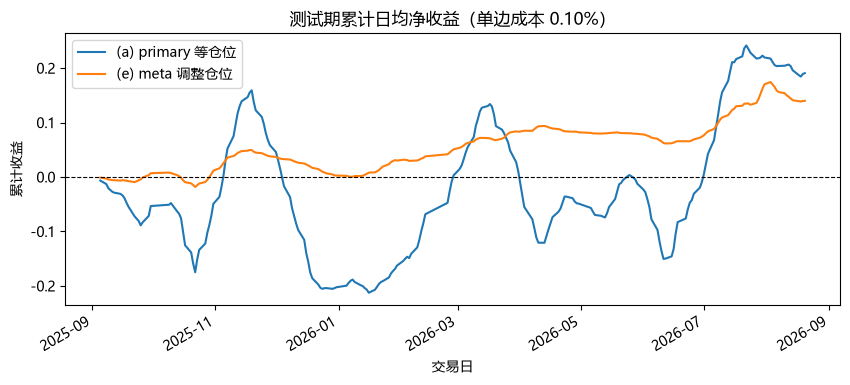

In [9]:
test['概率档'] = pd.qcut(test['meta概率'], 10, labels=False, duplicates='drop')
ladder = test.groupby('概率档').agg(平均概率=('meta概率', 'mean'),
                                    平均仓位=('仓位', 'mean'),
                                    主模型毛盈亏=('primary盈亏', 'mean'),
                                    meta毛收益=('meta盈亏', 'mean'),
                                    meta净收益=('meta净盈亏', 'mean'),
                                    样本数=('meta盈亏', 'size'))
# 判断 meta 的排序能力必须看未缩放的主模型每笔盈亏：仓位缩放会同时改变分子与分母，掩盖信号质量本身。
rho, p_value = stats.spearmanr(test['meta概率'], test['primary盈亏'])
rho_net, _ = stats.spearmanr(test['meta概率'], test['meta净盈亏'])
print(f'meta 概率 vs 主模型每笔毛盈亏：Spearman ρ = {rho:.4f}（p = {p_value:.2e}）')
print(f'meta 概率 vs 缩放后每笔净收益：Spearman ρ = {rho_net:.4f}')
display(ladder.round(5))

thin = test[test['窗口位置'] % PT == 0]
print(f'不重叠子样本只落在 {thin["窗口位置"].nunique()} 个交易日上，'
      f'Sharpe 的抽样噪声极大，仅用于估计重叠造成的虚高量级，不能当作策略有效的证据')
display(pd.DataFrame([
    summarize(thin['primary盈亏'], thin['样本外方向'], thin['事件日'], 'primary（不重叠）'),
    summarize(thin['meta盈亏'], thin['仓位'], thin['事件日'], 'meta 调整（不重叠）'),
]).round(4))

# 公募基金做空不可得，给出只做多变体作参考：主模型方向为 −1 时不下注。
long_frame = test.assign(多头仓位=np.where(test['样本外方向'] > 0,
                                          2.0 * test['meta概率'] - 1.0, 0.0))
long_frame = long_frame[long_frame['多头仓位'] > 0]
print(f'只做多变体保留 {len(long_frame)} 笔，占全部测试事件的 {len(long_frame) / len(test):.1%}')
display(pd.DataFrame([
    summarize(long_frame['多头仓位'] * long_frame['建仓收益'], long_frame['多头仓位'],
              long_frame['事件日'], '只做多 + meta'),
]).round(4))

fig, ax = plt.subplots()
for name, column in (('(a) primary 等仓位', 'primary净盈亏'), ('(e) meta 调整仓位', 'meta净盈亏')):
    curve = pd.Series(test[column].to_numpy(), index=test['事件日']).groupby(level=0).mean().cumsum()
    curve.plot(ax=ax, label=name)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set(title=f'测试期累计日均净收益（单边成本 {COST:.2%}）', xlabel='交易日', ylabel='累计收益')
ax.legend()
plt.show()

## 结论与限制

**1. (a) 的两层结构缓解了过拟合，但主模型的方向判别力在样本外大幅衰减**

方向 AUC 从样本内 0.632 降到样本外 0.521，三分类平衡准确率从 0.421 降到 0.364。
样本外三分类准确率 0.484 仍高于多数类基线 0.445，说明存在**微弱但可测**的信号；
但 0.521 的方向 AUC 意味着单靠 (a) 几乎不能决定该做多还是做空。
这也是后续 (d)(e) 存在的理由：既然方向本身不硬，就需要另一套机制来裁决「这笔下注值不值得」。

**2. (d) 的对照揭示了一个反直觉事实：硬标签几乎不含信息，但它反而带来了最好的组合**

| 方案 | 特征 | 测试期 AUC |
| --- | --- | --- |
| 仅方向（纯 meta） | 1 | 0.501 |
| 仅 p_up（纯 meta） | 1 | 0.542 |
| **特征 + 方向（练习 a，主方案）** | **9** | **0.552** |
| 特征 + p_up（对照） | 9 | 0.528 |

单独使用时，硬标签方向（即 `sign(p_up − p_down)`）的 AUC 只有 0.501，等同随机；而软概率 p_up 有 0.542。
这说明**主模型的置信度主要在概率值里，不在方向的符号里**。

但把硬标签与 8 个原始特征合并后达到 0.552，是四组里最高的；而把 p_up 与同样的原始特征合并反而降到 0.528（低于单独用 p_up）。
解读是：**原始特征（波动率、偏度、峰度与均线差）承担了绝大部分判别力，主模型预测只贡献很小一部分增量**；
硬标签与原始特征不冗余，而软概率与原始特征重叠严重，互相稀释。
这不否定 meta-labeling：题设要求的两层结构仍然成立，但**在本数据上「换一批特征」的增量远大于「加一个 label 特征」**。

**3. (e) 的 Sharpe 提升来自「按真实排序能力缩仓」**

按 meta 概率缩仓后，日频 Sharpe 从 1.03 升到 3.70（t 值从 0.99 升到 3.54），但累计净收益从 92.1 降到 67.8。
收益降而 Sharpe 升，说明这是**仓位收缩降低波动**的结果，不是收益增强。
与「随机缩仓」的区别在于：缩仓的依据（meta 概率）与后续盈亏真的相关（见下一点），
所以收缩发生在该收缩的地方。但即使如此，绝对收益仍低于等仓位 primary，
不能把 Sharpe 提升表述为「策略变好了」——它只是风险调整后的效率更高。

**4. 分档表证明 meta 模型确实在排序，但净收益呈 U 形是仓位符号造成的**

| 概率档 | 平均概率 | 主模型毛盈亏/笔 | meta 净收益/笔 |
| --- | --- | --- | --- |
| 0（最低） | 0.351 | −0.0048 | +0.0009 |
| 2 | 0.461 | +0.0014 | −0.0003 |
| 5 | 0.524 | +0.0030 | +0.0000 |
| 8 | 0.602 | +0.0062 | +0.0009 |
| 9（最高） | 0.685 | +0.0114 | +0.0041 |

**未缩放的主模型每笔毛盈亏从最低档 −0.48% 单调升到最高档 +1.14%**，跨度 1.62 个百分点，
Spearman ρ = 0.092（p ≈ 3×10⁻²⁰⁸）。这是 meta 模型在排序「这笔下注值不值」的直接证据，
且排序方向正确：概率越高，主模型方向越可能赚钱。

但缩放后的 meta 净收益呈 U 形而非单调：最低档 `2p−1 < 0` 把仓位翻到主模型方向的反面，
而该档主模型恰好亏钱，于是反向小仓位反而小赚；中间档仓位接近零，收益被压平。
因此「U 形」不是模型失效，而是**符号翻转的自然结果**。它同时提醒：低概率档的经济含义是
「主动做反向小注」，而不是「不下注」——若只想过滤，应显式把该档仓位置零。

**5. 不重叠子样本的 Sharpe 不能当证据**

每隔 `PT` 天取样后只剩 11 个交易日的截面，Sharpe 会出现异常高的数值。
它的价值仅在于说明「按日不等权聚合会让重叠事件的 Sharpe 虚高」，不能用来证明策略有效。

**6. 只做多变体的表现介于两者之间**

在基金不能做空的实际约束下，仅保留主模型做多的信号（只占测试事件 13.1%），
每笔净收益 0.0018、日频 Sharpe 1.34（t = 1.29），高于全样本 primary 但低于双侧 meta。
这说明 (a) 的方向信号里**做空那一半贡献了相当一部分收益**，而公募基金在公开市场基本无法做空——
这是该练习在本数据上最不能直接移植到实盘的一环。

**必须写明的限制**

- 测试期仅 231 个交易日（约一年），任何 Sharpe 与 AUC 的置信区间都很宽，不应据此推断长期有效性。
- 50 余万事件并非独立样本：488 只基金共享市场共同因子，且每个事件平均持有 9.5 天、彼此大量重叠。
- 回测是逐事件独立结算，不是连续复利的资金曲线；未计冲击成本、容量约束与滑点。
- 公募基金做空不可得，止盈/止损双侧障碍只是练习的忠实设定；文末只做多变体仅作参考，且样本量减半。
- 价格复权口径尚未确认，跨基金的价格水平差异可能影响均线差类特征的分布。

In [10]:
print(f'训练事件 {len(train)}，测试事件 {len(test)}，测试交易日 {test["窗口位置"].nunique()}')
print(f'meta 概率 Spearman ρ = {rho:.4f}，分档最高/最低档主模型毛盈亏差 = '
      f'{ladder["主模型毛盈亏"].iloc[-1] - ladder["主模型毛盈亏"].iloc[0]:.6f}')
print(f'子样本 {len(thin)} 事件，primary 与 meta 的净收益每笔 = '
      f'{summarize(thin["primary盈亏"], thin["样本外方向"], thin["事件日"], "p")["净收益/笔"]:.6f} / '
      f'{summarize(thin["meta盈亏"], thin["仓位"], thin["事件日"], "m")["净收益/笔"]:.6f}')

训练事件 485536，测试事件 112163，测试交易日 231
meta 概率 Spearman ρ = 0.0918，分档最高/最低档主模型毛盈亏差 = 0.016229
子样本 5341 事件，primary 与 meta 的净收益每笔 = -0.002730 / 0.001468
